Setup the Environment

In [2]:
from pathlib import Path
import pandas as pd  # works with table and dataframe
import numpy as np  # mathematical operations on columns
import matplotlib.pyplot as plt #charts and plots
import seaborn as sns #charts and plots


## 1. Load and Inspect

In [3]:
from pathlib import Path

raw = Path("../data/raw")   # ".." = go up one folder from notebooks/ to the project folder

sessions  = pd.read_csv(raw / "website_sessions.csv")
pageviews = pd.read_csv(raw / "website_pageviews.csv")
orders    = pd.read_csv(raw / "orders.csv")
items     = pd.read_csv(raw / "order_items.csv")
refunds   = pd.read_csv(raw / "order_item_refunds.csv")
products  = pd.read_csv(raw / "products.csv")

orders.head(10)


,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,20,20,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,104,104,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,147,147,1,1,49.99,19.49
3,4,2012-03-20 09:41:45,160,160,1,1,49.99,19.49
4,5,2012-03-20 11:28:15,177,177,1,1,49.99,19.49
5,6,2012-03-20 16:12:47,232,232,1,1,49.99,19.49
6,7,2012-03-20 17:03:41,241,241,1,1,49.99,19.49
7,8,2012-03-20 23:35:27,295,295,1,1,49.99,19.49
8,9,2012-03-21 02:35:01,304,304,1,1,49.99,19.49
9,10,2012-03-21 06:45:58,317,317,1,1,49.99,19.49


## 2. First look at each table

In [4]:
# Put all tables in a dictionary
tables = {
    "website_sessions": sessions,
    "website_pageviews": pageviews,
    "orders": orders,
    "order_items": items,
    "order_item_refunds": refunds,
    "products": products,
}

tables.keys()  # check the keys of the dictionary

dict_keys(['website_sessions', 'website_pageviews', 'orders', 'order_items', 'order_item_refunds', 'products'])

In [5]:
# Empty list; each loop step adds one row of facts about one table
rows = []

# Go through the dictionary one table at a time
# name = the table's name (text), df = the table itself
for name, df in tables.items():

    # Add one dictionary (= one row of the overview) to the list
    rows.append({
        "table": name,                                  # table name
        "rows": len(df),                                # number of rows
        "columns": df.shape[1],                         # number of columns (shape = (rows, columns))
        "duplicate_rows": df.duplicated().sum(),        # rows that are exact copies of an earlier row
        "cells_with_nulls": df.isna().sum().sum(),      # total empty cells (1st sum = per column, 2nd sum = whole table)
        "first_date": df["created_at"].min(),           # earliest date in the table
        "last_date": df["created_at"].max(),            # latest date in the table
    })

# Turn the list of rows into a table (DataFrame): one row per table
overview = pd.DataFrame(rows)

# Show the result
overview

,table,rows,columns,duplicate_rows,cells_with_nulls,first_date,last_date
0,website_sessions,472871,9,0,289901,2012-03-19 08:04:16,2015-03-19 07:59:08
1,website_pageviews,1188124,4,0,0,2012-03-19 08:04:16,2015-03-19 07:59:32
2,orders,32313,8,0,0,2012-03-19 10:42:46,2015-03-19 05:38:31
3,order_items,40025,7,0,0,2012-03-19 10:42:46,2015-03-19 05:38:31
4,order_item_refunds,1731,5,0,0,2012-04-06 11:32:43,2015-04-01 18:11:08
5,products,4,3,0,0,2012-03-19 08:00:00,2014-02-05 10:00:00


# 3. Close Look at Tables

3.1 Sessions Table

A. Look at the table

In [6]:
sessions.head(10)

,website_session_id,created_at,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer
0,1,2012-03-19 08:04:16,1,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
1,2,2012-03-19 08:16:49,2,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
2,3,2012-03-19 08:26:55,3,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
3,4,2012-03-19 08:37:33,4,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
4,5,2012-03-19 09:00:55,5,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
5,6,2012-03-19 09:05:46,6,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
6,7,2012-03-19 09:06:27,7,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
7,8,2012-03-19 09:17:17,8,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
8,9,2012-03-19 09:27:56,9,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
9,10,2012-03-19 09:35:37,10,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com


In [7]:
sessions.info()  # check the data types of the columns and how many non-null values there are
sessions.describe()  # summary statistics for numeric columns

<class 'pandas.DataFrame'>
RangeIndex: 472871 entries, 0 to 472870
Data columns (total 9 columns):
 #   Column              Non-Null Count   Dtype
---  ------              --------------   -----
 0   website_session_id  472871 non-null  int64
 1   created_at          472871 non-null  str  
 2   user_id             472871 non-null  int64
 3   is_repeat_session   472871 non-null  int64
 4   utm_source          389543 non-null  str  
 5   utm_campaign        389543 non-null  str  
 6   utm_content         389543 non-null  str  
 7   device_type         472871 non-null  str  
 8   http_referer        432954 non-null  str  
dtypes: int64(3), str(6)
memory usage: 32.5 MB


,website_session_id,user_id,is_repeat_session
count,472871.000000,472871.000000,472871.000000
mean,236436.000000,198037.970163,0.166119
std,136506.243908,111992.997798,0.372188
min,1.000000,1.000000,0.000000
25%,118218.500000,101966.500000,0.000000
50%,236436.000000,199483.000000,0.000000
75%,354653.500000,294433.000000,0.000000
max,472871.000000,394318.000000,1.000000


In [8]:
sessions.describe(include="all") # overall overview

,website_session_id,created_at,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer
count,472871.000000,472871,472871.000000,472871.000000,389543,389543,389543,472871,432954
unique,NaN,470444,NaN,NaN,3,4,6,2,3
top,NaN,2012-11-23 17:50:52,NaN,NaN,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
freq,NaN,3,NaN,NaN,316035,337615,282706,327027,351237
mean,236436.000000,NaN,198037.970163,0.166119,NaN,NaN,NaN,NaN,NaN
std,136506.243908,NaN,111992.997798,0.372188,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,1.000000,0.000000,NaN,NaN,NaN,NaN,NaN
25%,118218.500000,NaN,101966.500000,0.000000,NaN,NaN,NaN,NaN,NaN
50%,236436.000000,NaN,199483.000000,0.000000,NaN,NaN,NaN,NaN,NaN
75%,354653.500000,NaN,294433.000000,0.000000,NaN,NaN,NaN,NaN,NaN


B. Missing values in sessions

In [9]:
# What percentate of the sessions have no utm source?
# Count missing values per column
missing = sessions.isna().sum()

# Same as a percentage (mean of True/False = share of missing)
missing_pct = (sessions.isna().mean() * 100).round(2)

# Put both side by side in one table
pd.DataFrame({"missing": missing, "pct": missing_pct})


,missing,pct
website_session_id,0,0.00
created_at,0,0.00
user_id,0,0.00
is_repeat_session,0,0.00
utm_source,83328,17.62
utm_campaign,83328,17.62
utm_content,83328,17.62
device_type,0,0.00
http_referer,39917,8.44


In [10]:
# Are utm_source, utm_campaign and utm_content always missing together?
# Count rows where at least one is missing but not all three
utm_missing = sessions[["utm_source", "utm_campaign", "utm_content"]].isna()
(utm_missing.any(axis=1) & ~utm_missing.all(axis=1)).sum()

# they all are missing together, so we can just use utm_source to check for missing values

np.int64(0)

In [11]:
# In the crosstab, how many sessions have utm_source missing but http_referer filled? Those are organic search.
# Compare utm_source with http_referer
# fillna("missing") makes empty cells visible in the table
pd.crosstab(sessions["utm_source"].fillna("missing"),
            sessions["http_referer"].fillna("missing"))


http_referer,https://www.bsearch.com,https://www.gsearch.com,https://www.socialbook.com,missing
utm_source,,,,
bsearch,62823,0,0,0
gsearch,0,316035,0,0
missing,8209,35202,0,39917
socialbook,0,0,10685,0


**Findings – sessions**
- 472,871 sessions; no duplicate rows
- created_at is text → convert to datetime
- is_repeat_session is a 0/1 flag → keep as is (~17% of sessions are repeat visits)
- device_type: desktop 69%, mobile 31%
- utm_source / campaign / content = 3 levels of the same ad (source → campaign → ad)
- Missing UTMs (17.6%) are not errors:
  - utm missing + referer filled = organic or direct search (43,411) -  (35,202 + 8,209).- no paid ad and no campaign.
  - utm missing + referer missing = direct type-in (39,917) - direct visit without any ads and campaign
  - *Check: 43,411 + 39,917 = 83,328, exactly the number of missing UTMs.*
  → don't fill; create a traffic_channel column in cleaning
        - Leave the original columns as they are, and add one new column that gives every session a clear label: such as paid_search_brand, paid_search_non_brand, paid_social, organic search (missing - filled 39917) and direct_type_in (missing overall - 43411)
- Paid sources always match their referer (no inconsistencies)


**Decisions – sessions**
| Finding | Decision | Reason |
|---|---|---|
| created_at is text | Convert to datetime | Needed for time analysis (monthly trends, before/after launches) |
| Missing UTMs (17.6%) and referer (8.4%) | Keep as missing; add `traffic_channel` column | Missing = no paid ad (organic or direct). Filling would mislabel organic sessions and change the original data |


 2. Is there any duplicate values

In [12]:
# is there any duplicate session_id? (there should not be any)
sessions["website_session_id"].duplicated().sum()  # 0 means no duplicates, good

np.int64(0)

C. Session Dates
 - to cheack partial months
 - how much traffic grew over time

In [13]:
# Convert to dates temporarily, only for checking
session_dates = pd.to_datetime(sessions["created_at"])

# Sessions per month
sessions_per_month = session_dates.dt.to_period("M").value_counts().sort_index()
sessions_per_month


created_at
2012-03     1879
2012-04     3734
2012-05     3736
2012-06     3963
2012-07     4249
2012-08     6097
2012-09     6546
2012-10     8183
2012-11    14011
2012-12    10072
2013-01     6401
2013-02     7168
2013-03     6264
2013-04     7971
2013-05     8449
2013-06     8325
2013-07     8903
2013-08     9180
2013-09     9580
2013-10    10773
2013-11    14032
2013-12    15735
2014-01    14825
2014-02    16285
2014-03    15669
2014-04    17353
2014-05    18061
2014-06    17715
2014-07    19038
2014-08    18590
2014-09    19513
2014-10    21526
2014-11    25125
2014-12    29722
2015-01    25337
2015-02    23778
2015-03    15083
Freq: M, Name: count, dtype: int64

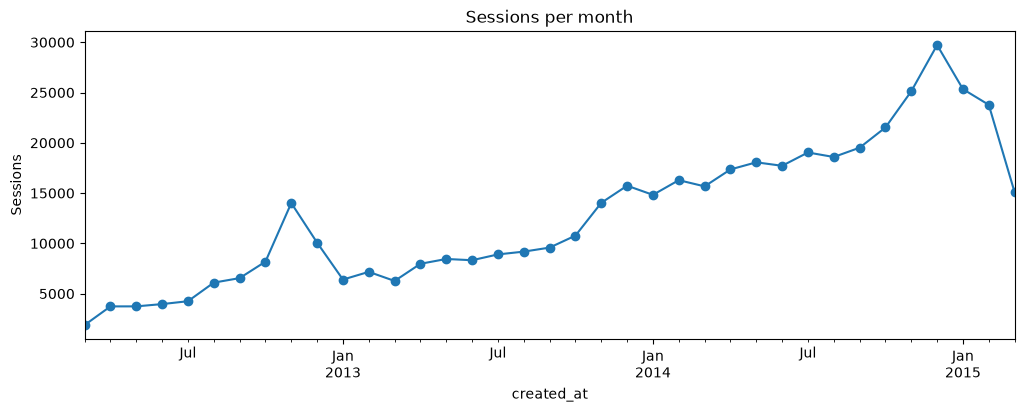

In [14]:


# Line chart: how traffic grew over time
sessions_per_month.plot(figsize=(12, 4), marker="o", title="Sessions per month")
plt.ylabel("Sessions")
plt.show()


**Findings – session dates**
- Website traffic grew steadily over the three years, from a few thousand sessions per month in 2012 to over 20,000 per month in early 2015.
  → Total sales and profit will rise partly because of traffic growth alone. Use per-order measures (profit per order, items per order) in the analysis, not just totals (traffic growth trap).
- Traffic peaks every November–December (holiday season), then drops in January.
  → Seasonality: compare the same periods year-over-year (e.g. Q4 vs Q4), not different quarters.
- March 2012 and March 2015 have lower counts because they are partial months (data starts and ends on the 19th), not because of a real drop.
  → Exclude them from monthly trends.

**Decision – session dates**
| Finding | Decision | Reason |
|---|---|---|
| First and last months are partial | Flag with `is_partial_month` in cleaning (don't delete) | Avoid fake drops in monthly trends; the data is still valid for totals |
| Strong traffic growth and Q4 peaks | No cleaning needed; note for analysis | Real business patterns, not data errors |

*Exact growth rates and percentages will be calculated in the SQL / Power BI analysis.*


# 3.2 Pageviews Table

A. Look at the table

In [15]:
# First rows: what does one row look like?
pageviews.head(10)


,website_pageview_id,created_at,website_session_id,pageview_url
0,1,2012-03-19 08:04:16,1,/home
1,2,2012-03-19 08:16:49,2,/home
2,3,2012-03-19 08:26:55,3,/home
3,4,2012-03-19 08:37:33,4,/home
4,5,2012-03-19 09:00:55,5,/home
5,6,2012-03-19 09:05:46,6,/home
6,7,2012-03-19 09:06:27,7,/home
7,8,2012-03-19 09:10:08,6,/products
8,9,2012-03-19 09:10:52,6,/the-original-mr-fuzzy
9,10,2012-03-19 09:14:02,6,/cart


In [16]:
# Data types and non-null counts
pageviews.info()
pageviews.describe(include="all")  # summary statistics for all columns


<class 'pandas.DataFrame'>
RangeIndex: 1188124 entries, 0 to 1188123
Data columns (total 4 columns):
 #   Column               Non-Null Count    Dtype
---  ------               --------------    -----
 0   website_pageview_id  1188124 non-null  int64
 1   created_at           1188124 non-null  str  
 2   website_session_id   1188124 non-null  int64
 3   pageview_url         1188124 non-null  str  
dtypes: int64(2), str(2)
memory usage: 36.3 MB


,website_pageview_id,created_at,website_session_id,pageview_url
count,1.188124e+06,1188124,1.188124e+06,1188124
unique,NaN,1171962,NaN,16
top,NaN,2013-11-29 07:34:02,NaN,/products
freq,NaN,4,NaN,261231
mean,5.940625e+05,NaN,2.444585e+05,NaN
std,3.429820e+05,NaN,1.356199e+05,NaN
min,1.000000e+00,NaN,1.000000e+00,NaN
25%,2.970318e+05,NaN,1.277860e+05,NaN
50%,5.940625e+05,NaN,2.478080e+05,NaN
75%,8.910932e+05,NaN,3.627390e+05,NaN


B. Duplicate Values

In [17]:
# Is there any duplicate values
pageviews["website_pageview_id"].duplicated().sum()


np.int64(0)

In [18]:
# Every page URL and how often it was viewed
pageviews["pageview_url"].value_counts()


pageview_url
/products                      261231
/the-original-mr-fuzzy         162525
/home                          137576
/lander-2                      131170
/cart                           94953
/lander-3                       79000
/lander-5                       68166
/shipping                       64484
/billing-2                      48441
/lander-1                       47574
/thank-you-for-your-order       32313
/the-forever-love-bear          26033
/the-birthday-sugar-panda       19046
/lander-4                        9385
/billing                         3617
/the-hudson-river-mini-bear      2610
Name: count, dtype: int64

1. Can we group the URLs? Think about the steps a customer goes through on the website, from landing on it to buying.
- we can group urls as there are 5 landing page, 4 products url, 2 biling, and more.
- home and landing pages - products and specific product 1-4 - landing- cart -shipping - biling - thankyou 

2. Which URLs are the 4 product pages?
- The 4 product pages: /the-original-mr-fuzzy, /the-forever-love-bear, /the-birthday-sugar-panda, /the-hudson-river-mini-bear


3. Do you see different versions of the same page (numbered 1, 2, …)?
- yes. 5 lander versions and 2 billing versions. These are website tests (A/B tests): the company tried different page designs to see which works better.

C. Pageviews per session + box plot (outliers)



In [19]:
# Count how many pages were viewed in each session
pv_per_session = pageviews.groupby("website_session_id").size()

# Summary statistics
pv_per_session.describe()


count    472871.000000
mean          2.512575
std           1.816384
min           1.000000
25%           1.000000
50%           2.000000
75%           3.000000
max           7.000000
dtype: float64

In [20]:
# How many sessions viewed 1 page, 2 pages, 3 pages, ...
pv_per_session.value_counts().sort_index()


1    211640
2     51017
3    115261
4     30469
5     12426
6     19745
7     32313
Name: count, dtype: int64

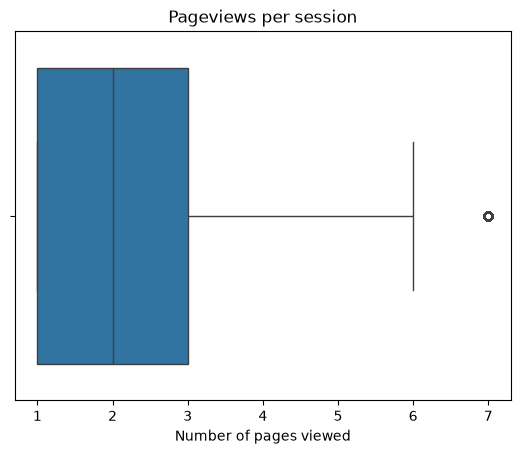

In [21]:
# Box plot to check for outliers
sns.boxplot(x=pv_per_session)
plt.title("Pageviews per session")
plt.xlabel("Number of pages viewed")
plt.show()


What is the most pages anyone viewed in one session? Is that suspicious (bots?) or normal?
- 7. That's not suspicious: it's the full path to a purchase, and nobody goes beyond it. There's no sign of bots.

How many sessions viewed only 1 page? What could that mean?
- On the box plot: 7 probably shows as a dot (outlier). That's only because of the box plot's math rule (most sessions view 1–3 pages). The value is real: they're buyers. So it's a statistical outlier, not a data error, and we will keep it.

Compare the count for the highest number of pages with the number of orders (32,313). Anything interesting?
- Only 1 page viewed? 211,640 sessions, almost half of all sessions. These visitors left from the landing page without clicking anything. This is called a bounce.

7 pages compared with orders? Both are 32,313. 7 pageviews = completed order.

D. Do pageviews link to sessions?

In [22]:
# Every pageview should belong to a real session (0 = good)
(~pageviews["website_session_id"].isin(sessions["website_session_id"])).sum()


np.int64(0)

In [23]:
# Does every session have at least one pageview? (0 = good)
(~sessions["website_session_id"].isin(pageviews["website_session_id"])).sum()


np.int64(0)

**Findings – pageviews**
- 1.19M pageviews; no missing values; no duplicate pageview IDs
- created_at is text → convert to datetime
- All pageviews link to a session, and every session has at least one pageview
- One session follows the purchase path: landing page (/home or /lander-1…5) → /products → product page → /cart → /shipping → /billing(-2) → /thank-you-for-your-order (7 pages)
- Sessions with 7 pageviews = completed orders (count matches the number of orders and thank-you pages)
- Almost half of sessions view only 1 page (bounce from the landing page)
- Pageviews per session range from 1 to 7. The box plot shows 7 as an outlier, but these are real purchases → keep
- Several page versions (/lander-1…5, /billing vs /billing-2) = website tests running during the period → context for "correlation vs causation"
- The Mini Bear product page gets very few views compared with other products → likely bought as a cart add-on (check in cross-sell analysis or this product was introduced in further date as a new product)

**Decisions – pageviews**
| Finding | Decision | Reason |
|---|---|---|
| created_at is text | Convert to datetime | Consistent with other tables |
| 7-pageview sessions flagged as outliers | Keep | Real complete purchase journeys, not errors |
| Supporting table for this project | No further cleaning | Not central to the product profitability question |


# 3.3 Orders Table

A. Look at the table

In [24]:
# First rows: what does one row look like?
orders.head(10)


,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,20,20,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,104,104,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,147,147,1,1,49.99,19.49
3,4,2012-03-20 09:41:45,160,160,1,1,49.99,19.49
4,5,2012-03-20 11:28:15,177,177,1,1,49.99,19.49
5,6,2012-03-20 16:12:47,232,232,1,1,49.99,19.49
6,7,2012-03-20 17:03:41,241,241,1,1,49.99,19.49
7,8,2012-03-20 23:35:27,295,295,1,1,49.99,19.49
8,9,2012-03-21 02:35:01,304,304,1,1,49.99,19.49
9,10,2012-03-21 06:45:58,317,317,1,1,49.99,19.49


In [25]:
# Data types, non-null counts and summary statistics
orders.info()
orders.describe()


<class 'pandas.DataFrame'>
RangeIndex: 32313 entries, 0 to 32312
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   order_id            32313 non-null  int64  
 1   created_at          32313 non-null  str    
 2   website_session_id  32313 non-null  int64  
 3   user_id             32313 non-null  int64  
 4   primary_product_id  32313 non-null  int64  
 5   items_purchased     32313 non-null  int64  
 6   price_usd           32313 non-null  float64
 7   cogs_usd            32313 non-null  float64
dtypes: float64(2), int64(5), str(1)
memory usage: 2.0 MB


,order_id,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
count,32313.000000,32313.000000,32313.000000,32313.000000,32313.000000,32313.000000,32313.000000
mean,16157.000000,258292.288707,215691.622629,1.392474,1.238666,59.991636,22.355406
std,9328.103961,132427.649842,108402.203189,0.732277,0.426274,17.808771,6.238621
min,1.000000,20.000000,13.000000,1.000000,1.000000,29.990000,9.490000
25%,8079.000000,144828.000000,124135.000000,1.000000,1.000000,49.990000,19.490000
50%,16157.000000,263554.000000,221461.000000,1.000000,1.000000,49.990000,19.490000
75%,24235.000000,374799.000000,310542.000000,2.000000,1.000000,59.990000,22.490000
max,32313.000000,472818.000000,394273.000000,4.000000,2.000000,109.980000,41.980000


B. Duplicate Values

In [26]:
# Each order ID should appear only once (0 = good)
orders["order_id"].duplicated().sum()


np.int64(0)

In [27]:
# Can one session have more than one order? (0 = each session has at most one order)
orders["website_session_id"].duplicated().sum()


np.int64(0)

C. Category like Numbe columns

In [28]:
# How many orders had 1 item, 2 items, ...?
orders["items_purchased"].value_counts().sort_index()



items_purchased
1    24601
2     7712
Name: count, dtype: int64

In [29]:
# How many orders had each product as the main product?
orders["primary_product_id"].value_counts().sort_index()

primary_product_id
1    23861
2     4803
3     3068
4      581
Name: count, dtype: int64

In [30]:
# Which order values exist, and how often?
orders["price_usd"].value_counts().sort_index()




price_usd
29.99       534
45.99      2039
49.99     18104
59.99      3924
75.98       662
79.98      3142
89.98       680
95.98      2036
105.98      248
109.98      944
Name: count, dtype: int64

In [38]:
#  Count orders for each order value, split by number of items (1 or 2)
pd.crosstab(orders["price_usd"], orders["items_purchased"])

items_purchased,1,2
price_usd,,
29.99,534,0
45.99,2039,0
49.99,18104,0
59.99,3924,0
75.98,0,662
79.98,0,3142
89.98,0,680
95.98,0,2036
105.98,0,248


What is the most items in one order?
- Most 1 items are purchased in one order.

Which product is the main product most often?
- Product 1 but it may be beacuse it is one of the oldest product of the shop.

How many different order values are there? Can you match them to product prices from your project notes ($49.99, $59.99, $45.99, $29.99)?
- the max price of a item in 59.99, the  price gretaer than 59.99 are the prices if the customer order 2 items as the same time

D. Outliers (box plot)

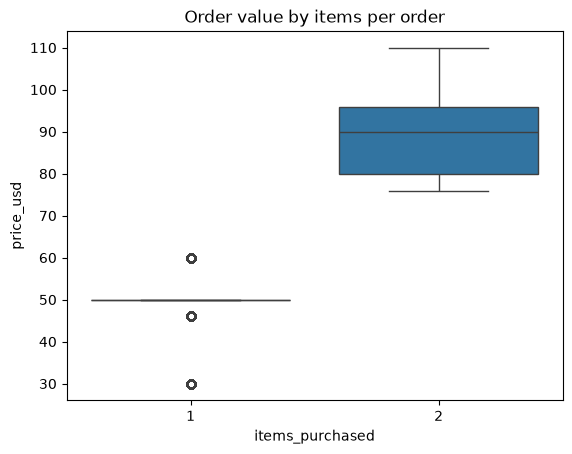

In [31]:
# Order value split by number of items in the order
sns.boxplot(data=orders, x="items_purchased", y="price_usd")
plt.title("Order value by items per order")
plt.show()

# Box plot: two clear groups. 1-item orders sit around $30–60 and 2-item orders around $76–110. Any dots are real product combinations, not errors


E. How the columns relate (correlation + scatter)

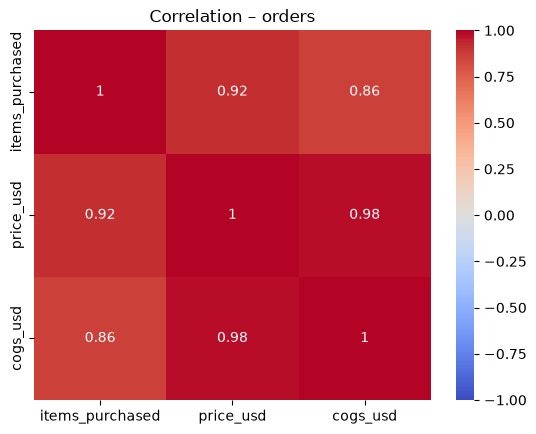

In [32]:
# Correlation between the real measures (no ID columns)
num_cols = ["items_purchased", "price_usd", "cogs_usd"]

sns.heatmap(orders[num_cols].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation – orders")
plt.show()


# all three measures are strongly positively related. Price and cost are almost perfectly
#  related, because each product has a fixed price and a fixed cost.
#  More items means higher price and higher cost. That's expected, not a discovery.


F. Orders over time

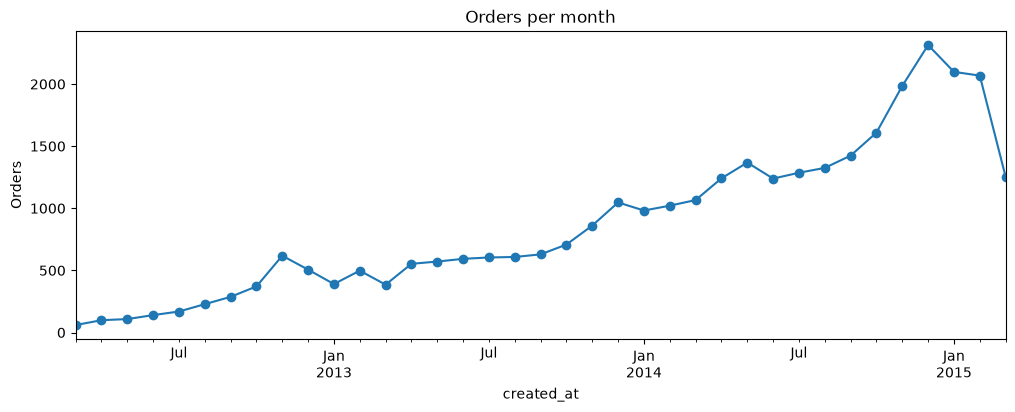

In [33]:
# Orders per month (temporary date conversion, only for checking)
order_dates = pd.to_datetime(orders["created_at"])
orders_per_month = order_dates.dt.to_period("M").value_counts().sort_index()

orders_per_month.plot(figsize=(12, 4), marker="o", title="Orders per month")
plt.ylabel("Orders")
plt.show()

# Orders over time: the same shape as the sessions chart: 
# growth over time, Q4 peaks, and lower partial months at the start and end.


G. Links to sessions

In [34]:
# Every order should belong to a real session (0 = good)
(~orders["website_session_id"].isin(sessions["website_session_id"])).sum()


np.int64(0)

In [35]:
# The user in the order should be the same user as in the session (0 = good)
check = orders.merge(sessions[["website_session_id", "user_id"]],
                     on="website_session_id", suffixes=("_order", "_session"))
(check["user_id_order"] != check["user_id_session"]).sum()


np.int64(0)

**Findings – orders**
- 32,313 orders; no missing values; no duplicate order IDs
- Each session has at most one order; every order links to a real session, and the user matches the session's user
- created_at is text → convert to datetime
- Orders contain 1 or 2 items; most orders have 1 item
- Mr. Fuzzy (product 1) is the main product in most orders – it was the only product for the first ~10 months, so this is expected
- There are 10 different order values: the 4 single-product prices and 6 two-product combinations. All values match real product prices → no wrong or impossible values
- The Mini Bear ($29.99) appears in many of the 2-item combinations → supports the idea that it is mainly an add-on (check in cross-sell analysis)
- Box plot: 1-item and 2-item orders form two separate groups; high values are real 2-item orders, not outliers to remove
- Correlation: items, price and cost are strongly positively related. Expected, because each product has a fixed price and cost
- Orders over time follow the same pattern as sessions: growth, Q4 peaks and partial first/last months

**Decisions – orders**
| Finding | Decision | Reason |
|---|---|---|
| created_at is text | Convert to datetime | Needed for before/after launch comparisons |
| High order values (2-item orders) | Keep | Real product combinations, not errors |
| Partial first/last months | Flag with `is_partial_month` | Same as sessions; avoid fake drops in trends |
| No profit column | Add `profit_usd` = price_usd − cogs_usd in cleaning | Profit per order is the main measure for the business question |


# 3.4. Order items table

A. Look at table

In [36]:
# First rows: what does one row look like?
items.head(10)


,order_item_id,created_at,order_id,product_id,is_primary_item,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,1,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,2,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,3,1,1,49.99,19.49
3,4,2012-03-20 09:41:45,4,1,1,49.99,19.49
4,5,2012-03-20 11:28:15,5,1,1,49.99,19.49
5,6,2012-03-20 16:12:47,6,1,1,49.99,19.49
6,7,2012-03-20 17:03:41,7,1,1,49.99,19.49
7,8,2012-03-20 23:35:27,8,1,1,49.99,19.49
8,9,2012-03-21 02:35:01,9,1,1,49.99,19.49
9,10,2012-03-21 06:45:58,10,1,1,49.99,19.49


In [37]:
# Data types, non-null counts and summary statistics
items.info()
items.describe()


<class 'pandas.DataFrame'>
RangeIndex: 40025 entries, 0 to 40024
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_item_id    40025 non-null  int64  
 1   created_at       40025 non-null  str    
 2   order_id         40025 non-null  int64  
 3   product_id       40025 non-null  int64  
 4   is_primary_item  40025 non-null  int64  
 5   price_usd        40025 non-null  float64
 6   cogs_usd         40025 non-null  float64
dtypes: float64(2), int64(4), str(1)
memory usage: 2.1 MB


,order_item_id,order_id,product_id,is_primary_item,price_usd,cogs_usd
count,40025.000000,40025.000000,40025.000000,40025.000000,40025.000000,40025.000000
mean,20013.000000,17121.957502,1.770019,0.807320,48.432473,18.047976
std,11554.366599,9053.765867,1.085561,0.394408,8.012370,3.856821
min,1.000000,1.000000,1.000000,0.000000,29.990000,9.490000
25%,10007.000000,9871.000000,1.000000,1.000000,49.990000,19.490000
50%,20013.000000,17490.000000,1.000000,1.000000,49.990000,19.490000
75%,30019.000000,24818.000000,2.000000,1.000000,49.990000,19.490000
max,40025.000000,32313.000000,4.000000,1.000000,59.990000,22.490000


B. Duplicates

In [39]:
items["order_item_id"].duplicated().sum() 

np.int64(0)

C. Category-like columns

In [41]:
# How many items were the main item (1) vs an add-on (0)?
print(items["is_primary_item"].value_counts())


# How many times was each product sold?
print(items["product_id"].value_counts().sort_index())

# Each product: how often sold as the main item vs as an add-on
print(pd.crosstab(items["product_id"], items["is_primary_item"]))

# Mr. Fuzzy is mostly the main item; Mini Bear is mostly an add-on (cross-sell product); Love Bear and Sugar Panda are sold both ways

is_primary_item
1    32313
0     7712
Name: count, dtype: int64
product_id
1    24226
2     5796
3     4985
4     5018
Name: count, dtype: int64
is_primary_item     0      1
product_id                  
1                 365  23861
2                 993   4803
3                1917   3068
4                4437    581


D. Price and cost per product

In [42]:
# Does each product always have the same price and cost?
items.groupby("product_id")[["price_usd", "cogs_usd"]].agg(["min", "max", "nunique"])


# None of the products have different prices or costs. They donot vary over time, and they don't vary between orders.
# Each product has a fixed price and a fixed cost, which is why price and cost are almost perfectly correlated in the orders table.


price_usd                cogs_usd               
                 min    max nunique      min    max nunique
product_id                                                 
1              49.99  49.99       1    19.49  19.49       1
2              59.99  59.99       1    22.49  22.49       1
3              45.99  45.99       1    14.49  14.49       1
4              29.99  29.99       1     9.49   9.49       1

E. Links to other tables

In [46]:
# Every item should belong to a real order (0 = good)
print((~items["order_id"].isin(orders["order_id"])).sum())

# Every item should be a known product (0 = good)
print((~items["product_id"].isin(products["product_id"])).sum())


0
0


F. Do orders match their items?


In [44]:
# Add up the items for each order
item_totals = items.groupby("order_id").agg(
    n_items=("order_item_id", "count"),      # number of items in the order
    price_sum=("price_usd", "sum"),          # total price of the items
    cogs_sum=("cogs_usd", "sum"),            # total cost of the items
    n_primary=("is_primary_item", "sum"),    # number of main items
)

# Put the item totals next to each order
check = orders.set_index("order_id").join(item_totals)

# Each line counts problem orders (0 = good)
print("items_purchased ≠ number of items:", (check["items_purchased"] != check["n_items"]).sum())
print("price_usd ≠ sum of item prices:  ", ((check["price_usd"] - check["price_sum"]).abs() > 0.01).sum())
print("cogs_usd ≠ sum of item costs:    ", ((check["cogs_usd"] - check["cogs_sum"]).abs() > 0.01).sum())
print("orders without exactly 1 main item:", (check["n_primary"] != 1).sum())


items_purchased ≠ number of items: 0
price_usd ≠ sum of item prices:   0
cogs_usd ≠ sum of item costs:     0
orders without exactly 1 main item: 0


G. Sold before launch?

In [45]:
# Was any product sold before its launch date? (0 = good)
check_launch = items.merge(products[["product_id", "created_at"]],
                           on="product_id", suffixes=("_item", "_launch"))
(pd.to_datetime(check_launch["created_at_item"]) < pd.to_datetime(check_launch["created_at_launch"])).sum()


np.int64(0)

**Findings – order_items**
- 40,025 items; no missing values or duplicate IDs; created_at is text → convert to datetime
- One row = one product in an order; every order has exactly one main item
- Mr. Fuzzy is mostly the main item; Mini Bear is mostly an add-on (cross-sell product); Love Bear and Sugar Panda are sold both ways
- Each product has a fixed price and cost → profit changes come from product mix and cross-sell, not price changes
- All items link to a real order and product; order totals match their items; no product sold before launch

**Decisions – order_items**
| Finding | Decision | Reason |
|---|---|---|
| created_at is text | Convert to datetime | Before/after launch comparisons |
| No profit or refund info | Add `profit_usd`, `is_refunded`, `refund_amount_usd`, `net_profit_usd` | Profit by product, before and after refunds |


3.5. Products Table

A. Look at the whole table

In [47]:
# Only 4 rows, so show everything
products


,product_id,created_at,product_name
0,1,2012-03-19 08:00:00,The Original Mr. Fuzzy
1,2,2013-01-06 13:00:00,The Forever Love Bear
2,3,2013-12-12 09:00:00,The Birthday Sugar Panda
3,4,2014-02-05 10:00:00,The Hudson River Mini bear


In [48]:
# Data types and non-null counts
products.info()


<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   product_id    4 non-null      int64
 1   created_at    4 non-null      str  
 2   product_name  4 non-null      str  
dtypes: int64(1), str(2)
memory usage: 228.0 bytes


D. Launch Dates

In [ ]:
# Convert to dates temporarily, only for checking
launch_dates = pd.to_datetime(products["created_at"])

# Days between each launch and the one before
products.assign(launch_date=launch_dates,     # assign() adds the new columns only for display.
                                days_since_previous=launch_dates.diff().dt.days)


,product_id,created_at,product_name,launch_date,days_since_previous
0,1,2012-03-19 08:00:00,The Original Mr. Fuzzy,2012-03-19 08:00:00,NaN
1,2,2013-01-06 13:00:00,The Forever Love Bear,2013-01-06 13:00:00,293.0
2,3,2013-12-12 09:00:00,The Birthday Sugar Panda,2013-12-12 09:00:00,339.0
3,4,2014-02-05 10:00:00,The Hudson River Mini bear,2014-02-05 10:00:00,55.0


**Findings – products**
- 4 products; no missing values; each product appears once
- created_at = launch date, stored as text → convert to datetime and rename to `launched_at` so its meaning is clear
- Product names are inconsistent: "The Hudson River Mini **bear**" uses a lowercase "bear", while the others use capitals → standardise to "Mini Bear"
- Launch timeline:
  - Mr. Fuzzy was the only product for about 10 months (Mar 2012 → Jan 2013)
  - Love Bear and Sugar Panda launched roughly a year apart
  - Sugar Panda and Mini Bear launched less than 2 months apart (Dec 2013 → Feb 2014)
    → their effects will be hard to separate in before/after comparisons; may need to analyse them together
- Sugar Panda launched in December → its first weeks fall in the holiday peak, so compare with care (seasonality)

**Decisions – products**
| Finding | Decision | Reason |
|---|---|---|
| created_at is text | Convert to datetime; rename to `launched_at` | Used as the official launch date for before/after windows |
| "Mini bear" lowercase | Standardise to "Mini Bear" | Consistent labels in charts and Power BI |
| Long product names | Add `product_short_name` (Mr. Fuzzy, Love Bear, Sugar Panda, Mini Bear) | Shorter, cleaner labels in charts |


3.6. Refunds Table

In [50]:
# First rows and data types
refunds.head()


,order_item_refund_id,created_at,order_item_id,order_id,refund_amount_usd
0,1,2012-04-06 11:32:43,57,57,49.99
1,2,2012-04-13 01:09:43,74,74,49.99
2,3,2012-04-15 07:03:48,71,71,49.99
3,4,2012-04-17 20:00:37,118,118,49.99
4,5,2012-04-22 20:53:49,116,116,49.99


In [51]:
refunds.info()
refunds.describe()


<class 'pandas.DataFrame'>
RangeIndex: 1731 entries, 0 to 1730
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   order_item_refund_id  1731 non-null   int64  
 1   created_at            1731 non-null   str    
 2   order_item_id         1731 non-null   int64  
 3   order_id              1731 non-null   int64  
 4   refund_amount_usd     1731 non-null   float64
dtypes: float64(1), int64(3), str(1)
memory usage: 67.7 KB


,order_item_refund_id,order_item_id,order_id,refund_amount_usd
count,1731.000000,1731.000000,1731.000000,1731.000000
mean,866.000000,18472.214905,15868.242057,49.300225
std,499.840975,11438.074606,9096.061945,4.956015
min,1.000000,57.000000,57.000000,29.990000
25%,433.500000,7417.000000,7412.000000,49.990000
50%,866.000000,19858.000000,17375.000000,49.990000
75%,1298.500000,26900.000000,22539.500000,49.990000
max,1731.000000,39950.000000,32255.000000,59.990000


B. Duplicates

In [ ]:
# Each refund ID should appear only once
print(refunds["order_item_refund_id"].duplicated().sum())

# Each item should be refunded at most once 
print(refunds["order_item_id"].duplicated().sum())


0
0


C. Links to order_items

In [53]:
# Every refund should belong to a real order item (0 = good)
print((~refunds["order_item_id"].isin(items["order_item_id"])).sum())


0


In [54]:
# Join each refund with its order item to compare them
ref_check = refunds.merge(items[["order_item_id", "order_id", "product_id", "price_usd", "created_at"]],
                          on="order_item_id", suffixes=("_refund", "_item"))

# The order_id in the refund should match the item's order_id (0 = good)
print((ref_check["order_id_refund"] != ref_check["order_id_item"]).sum())


0


D. Refund amounts

In [55]:
# Refund larger than the item price? (0 = good)
print((ref_check["refund_amount_usd"] > ref_check["price_usd"]).sum())

# Partial refunds (less than the item price)?
print((ref_check["refund_amount_usd"] < ref_check["price_usd"]).sum())


0
0


E. Refund timing + box plot

In [56]:
# Days between the order and the refund
ref_check["days_to_refund"] = (pd.to_datetime(ref_check["created_at_refund"])
                               - pd.to_datetime(ref_check["created_at_item"])).dt.days

# Refund before the order? (0 = good)
print((ref_check["days_to_refund"] < 0).sum())

ref_check["days_to_refund"].describe()


0


count    1731.000000
mean        8.545927
std         4.033895
min         2.000000
25%         5.000000
50%         9.000000
75%        12.000000
max        16.000000
Name: days_to_refund, dtype: float64

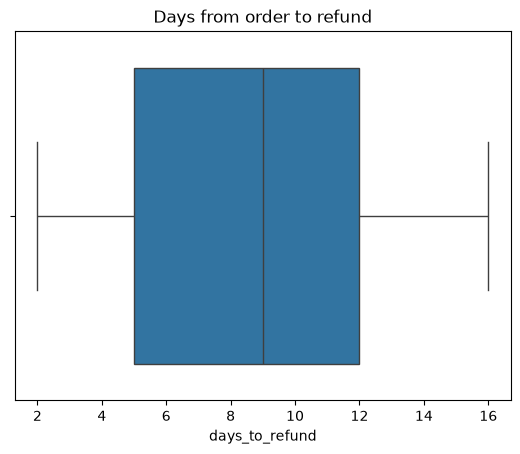

In [57]:
# Box plot of days to refund (outliers?)
sns.boxplot(x=ref_check["days_to_refund"])
plt.title("Days from order to refund")
plt.show()


F. Refunds per product

In [58]:
# Number of refunds per product
ref_check["product_id"].value_counts().sort_index()


product_id
1    1237
2     129
3     301
4      64
Name: count, dtype: int64

**Findings – refunds**
- 1,731 refunds; no missing values or duplicates; created_at is text → convert to datetime
- Each item is refunded at most once; every refund links to a real order item with the matching order
- All refunds are full refunds (refund = item price); none are larger than the price
- Refunds happen 2–16 days after the order; no refunds before the order, no unusual outliers
- Mr. Fuzzy and Sugar Panda seem to be refunded more often than Love Bear and Mini Bear, compared with how many were sold (exact refund rates in the analysis)
  → orders from the last ~2 weeks of data may still get refunds that aren't in the data, so their refund rates look too low

**Decisions – refunds**
| Finding | Decision | Reason |
|---|---|---|
| created_at is text | Convert to datetime | Refund trends over time |
| Refunds are separate from items | Join to order_items: add `is_refunded`, `refund_amount_usd`, `net_profit_usd` | Profit after refunds by product |
| Last ~2 weeks of orders incomplete for refunds | Keep; leave out of refund-rate analysis | Avoid understating refund rates |
